<a href="https://colab.research.google.com/github/s31302/suml_projekt/blob/main/suml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importowanie danych z lokalnego dysku
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
path = '/content/drive/MyDrive/data/'
housing = pd.read_csv(path + 'airbnb_train.csv', header='infer')

Mounted at /content/drive


In [ ]:
housing.shape

(208856, 52)

In [ ]:
housing.columns

Index(['id', 'name', 'description', 'neighborhood_overview', 'host_id',
       'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bedrooms', 'beds', 'amenities', 'price', 'has_availability',
       'availability_30', 'availability_60', 'availability_90',
       'availability_365', 'number_of_reviews', 'number_of_reviews_ltm',
       'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly',
       'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'first_review',
       'last_review', 'review_scores_rating', 'review_scores_accuracy',
       'review_scores_cleanliness', 'review_scores_checkin',
       'review

In [ ]:
kolumy = housing.columns

for i in kolumy:
  print(f"{i} = {housing[i].nunique()}")

id = 208856
name = 204722
description = 188402
neighborhood_overview = 90016
host_id = 143588
host_name = 38814
host_since = 5592
host_location = 9125
host_about = 62946
host_response_time = 4
host_response_rate = 100
host_acceptance_rate = 101
host_is_superhost = 2
host_neighbourhood = 7538
host_listings_count = 722
host_total_listings_count = 875
host_verifications = 8
host_has_profile_pic = 2
host_identity_verified = 2
latitude = 190084
longitude = 193388
property_type = 136
room_type = 4
accommodates = 16
bathrooms = 36
bedrooms = 29
beds = 42
amenities = 200383
price = 997
has_availability = 2
availability_30 = 31
availability_60 = 61
availability_90 = 91
availability_365 = 366
number_of_reviews = 913
number_of_reviews_ltm = 254
number_of_reviews_l30d = 40
availability_eoy = 318
number_of_reviews_ly = 223
estimated_occupancy_l365d = 139
estimated_revenue_l365d = 9442
first_review = 4878
last_review = 2913
review_scores_rating = 196
review_scores_accuracy = 189
review_scores_cleanl

In [ ]:
polowa = len(housing)/2
tab = []

for col_name in housing.columns:
    print(f"{type(housing[col_name][0])} {col_name} {housing[col_name].isnull().sum()}")

    if type(housing[col_name][0]) == str or type(housing[col_name][0]) == float:
        tab.append(col_name)

    if housing[col_name].isnull().sum() >= polowa:
        print(f"======== {col_name} - {housing[col_name].isnull().sum()} =========")

print(len(tab))

<class 'numpy.int64'> id 0
<class 'str'> name 0
<class 'str'> description 4873
<class 'str'> neighborhood_overview 107040
======== neighborhood_overview - 107040 =========
<class 'numpy.int64'> host_id 0
<class 'str'> host_name 92
<class 'str'> host_since 99
<class 'str'> host_location 53279
<class 'str'> host_about 100662
<class 'str'> host_response_time 31961
<class 'str'> host_response_rate 31961
<class 'str'> host_acceptance_rate 17970
<class 'str'> host_is_superhost 5841
<class 'float'> host_neighbourhood 126725
======== host_neighbourhood - 126725 =========
<class 'numpy.float64'> host_listings_count 99
<class 'numpy.float64'> host_total_listings_count 99
<class 'str'> host_verifications 99
<class 'str'> host_has_profile_pic 99
<class 'str'> host_identity_verified 99
<class 'numpy.float64'> latitude 0
<class 'numpy.float64'> longitude 0
<class 'str'> property_type 0
<class 'str'> room_type 0
<class 'numpy.int64'> accommodates 0
<class 'numpy.float64'> bathrooms 98
<class 'numpy.f

### 1. Importowanie bibliotek i konfiguracja wykresów

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Konfiguracja stylu wykresów
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### 2. Podstawowe statystyki i sprawdzenie braków danych

In [ ]:
# Informacje o typach danych i podstawowe statystyki opisowe
housing.info()
display(housing.describe(include="all"))

# Sprawdzenie braków danych (top 15 kolumn)
missing_data = housing.isnull().sum().sort_values(ascending=False)
print("Top 15 kolumn z największą liczbą braków danych:")
print(missing_data.head(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208856 entries, 0 to 208855
Data columns (total 52 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           208856 non-null  int64  
 1   name                         208856 non-null  object 
 2   description                  203983 non-null  object 
 3   neighborhood_overview        101816 non-null  object 
 4   host_id                      208856 non-null  int64  
 5   host_name                    208764 non-null  object 
 6   host_since                   208757 non-null  object 
 7   host_location                155577 non-null  object 
 8   host_about                   108194 non-null  object 
 9   host_response_time           176895 non-null  object 
 10  host_response_rate           176895 non-null  object 
 11  host_acceptance_rate         190886 non-null  object 
 12  host_is_superhost            203015 non-null  object 
 13 

,id,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,host_response_time,...,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,city
count,208856.000000,208856,203983,101816,2.088560e+05,208764,208757,155577,108194,176895,...,168211,168210.000000,168203.000000,168203.000000,168197.000000,168202.000000,168199.000000,168198.000000,168211.000000,208856
unique,NaN,204722,188402,90016,NaN,38814,5592,9125,62946,4,...,2913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108
top,NaN,Home away from home,Relax with the whole family at this peaceful p...,"Antwerp is Belgium’s second-largest city, has ...",NaN,Blueground,2016-12-16,"Paris, France","We’re Blueground, a global proptech company wi...",within an hour,...,2024-12-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,London
freq,NaN,41,377,41,NaN,1401,925,8959,863,133865,...,2438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13464
mean,130910.285915,NaN,NaN,NaN,2.203708e+08,NaN,NaN,NaN,NaN,NaN,...,NaN,4.748524,4.777869,4.739318,4.830276,4.838841,4.777121,4.662327,1.433898,NaN
std,75665.531201,NaN,NaN,NaN,2.030446e+08,NaN,NaN,NaN,NaN,NaN,...,NaN,0.393226,0.376937,0.403565,0.342427,0.344466,0.333982,0.424348,1.722879,NaN
min,1.000000,NaN,NaN,NaN,2.900000e+01,NaN,NaN,NaN,NaN,NaN,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000,NaN
25%,65293.500000,NaN,NaN,NaN,3.529497e+07,NaN,NaN,NaN,NaN,NaN,...,NaN,4.670000,4.730000,4.670000,4.800000,4.820000,4.700000,4.570000,0.300000,NaN
50%,130964.500000,NaN,NaN,NaN,1.461081e+08,NaN,NaN,NaN,NaN,NaN,...,NaN,4.860000,4.890000,4.860000,4.930000,4.950000,4.880000,4.760000,0.860000,NaN
75%,196472.500000,NaN,NaN,NaN,4.142567e+08,NaN,NaN,NaN,NaN,NaN,...,NaN,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.910000,2.000000,NaN


Top 15 kolumn z największą liczbą braków danych:
host_neighbourhood             126725
number_of_reviews_ly           111467
estimated_occupancy_l365d      111467
estimated_revenue_l365d        111467
availability_eoy               111467
neighborhood_overview          107040
host_about                     100662
host_location                   53279
review_scores_checkin           40659
review_scores_value             40658
review_scores_location          40657
review_scores_communication     40654
review_scores_accuracy          40653
review_scores_cleanliness       40653
review_scores_rating            40646
dtype: int64


### 3. Rozkład zmiennej docelowej (Cena)

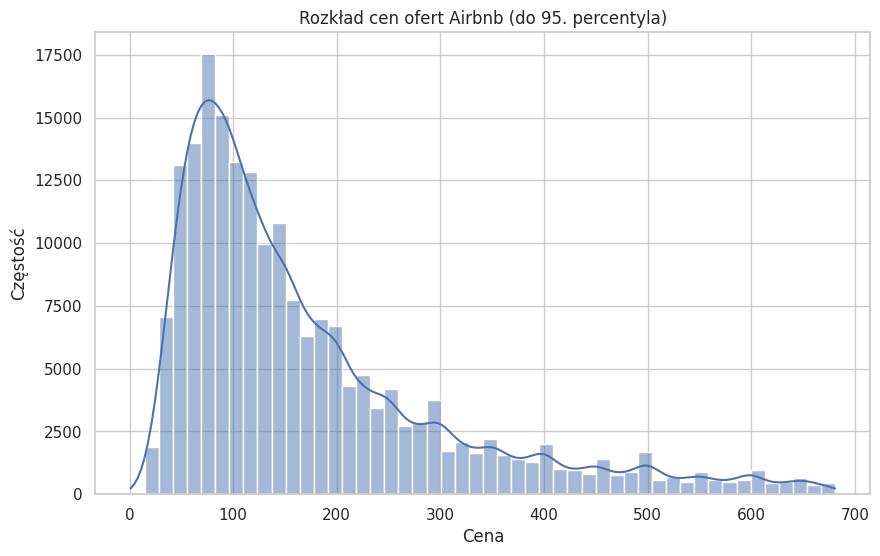

In [ ]:
q_limit = housing['price'].quantile(0.95)
sns.histplot(housing[housing['price'] < q_limit]['price'], bins=50, kde=True)
plt.title('Rozkład cen ofert Airbnb (do 95. percentyla)')
plt.xlabel('Cena')
plt.ylabel('Częstość')
plt.show()

### 4. Analiza: Typ pokoju (room_type) a cena

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# import pandas as pd
# path = '/content/drive/MyDrive/data/'
# housing = pd.read_csv(path + 'airbnb_train.csv', header='infer')

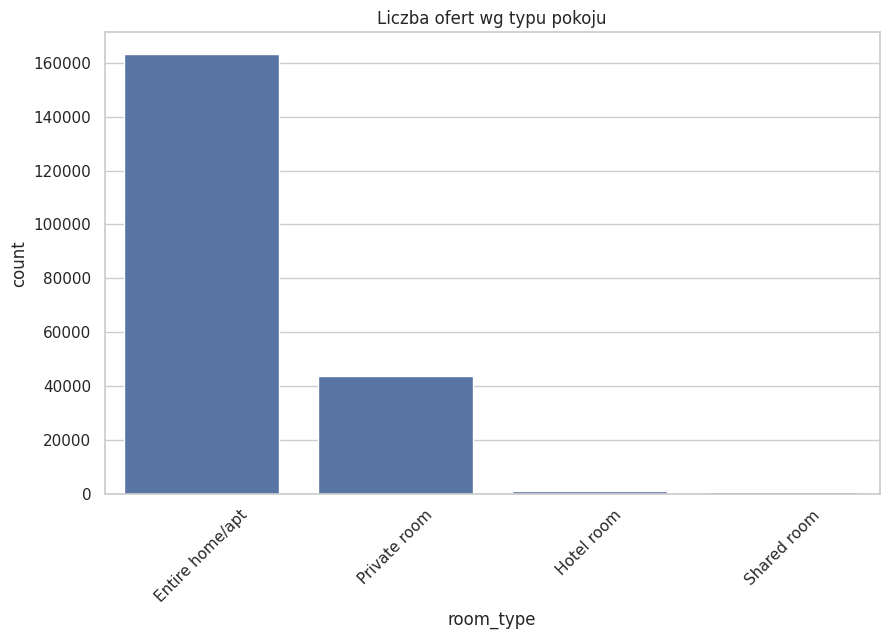

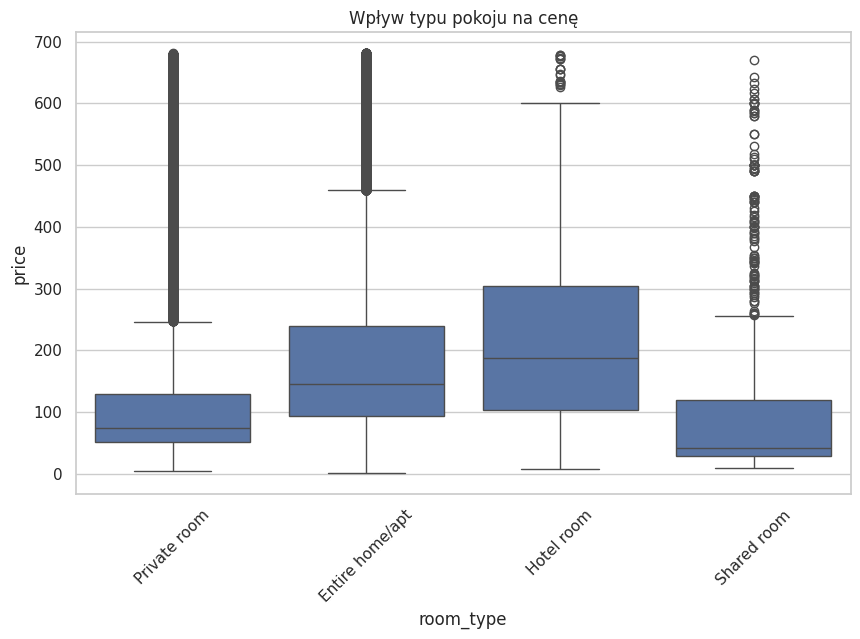

In [ ]:
# Liczba ofert w zależności od typu pokoju
sns.countplot(data=housing, x='room_type', order=housing['room_type'].value_index if hasattr(housing['room_type'], 'value_index') else housing['room_type'].value_counts().index)
plt.title('Liczba ofert wg typu pokoju')
plt.xticks(rotation=45)
plt.show()

sns.boxplot(data=housing[housing['price'] < q_limit], x='room_type', y='price')
plt.title('Wpływ typu pokoju na cenę')
plt.xticks(rotation=45)
plt.show()

### 5. Analiza: Miasto (city) a cena

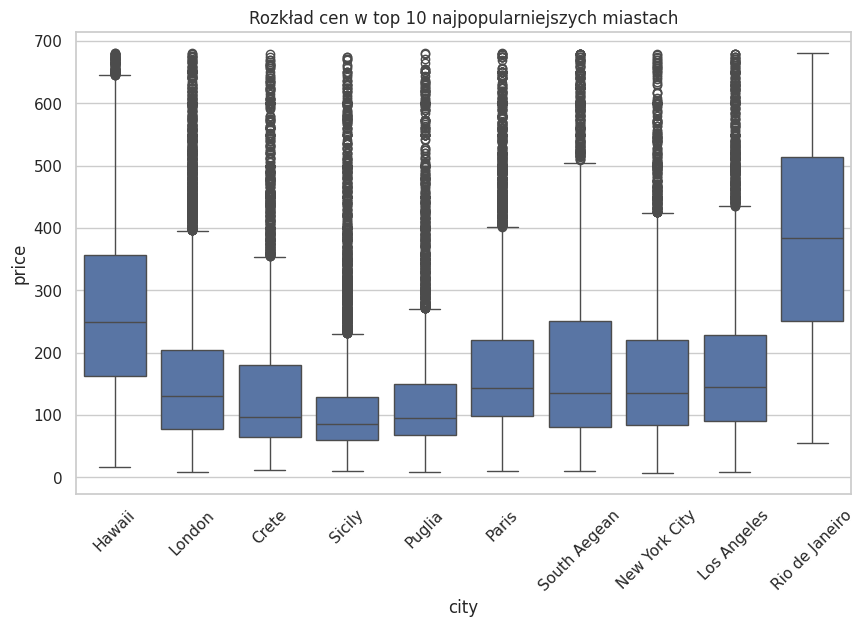

In [ ]:
# Top 10 najpopularniejszych miast w zbiorze danych
top_cities = housing['city'].value_counts().head(10).index
housing_top_cities = housing[housing['city'].isin(top_cities)]

sns.boxplot(data=housing_top_cities[housing_top_cities['price'] < q_limit], x='city', y='price')
plt.title('Rozkład cen w top 10 najpopularniejszych miastach')
plt.xticks(rotation=45)
plt.show()

### 6. Tworzenie i analiza nowych cech

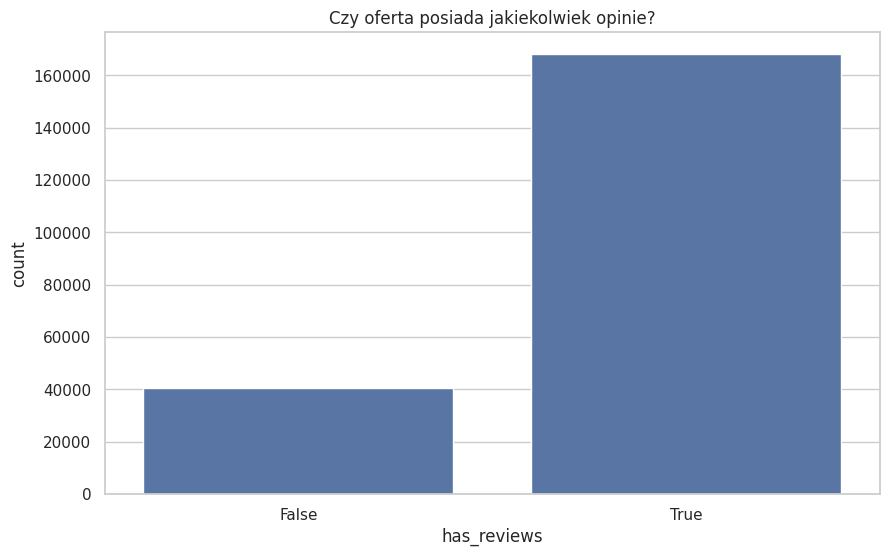

In [ ]:
# Tworzenie nowych cech: pojemność na sypialnię oraz informacja czy obiekt ma jakiekolwiek oceny
housing['beds_per_bedroom'] = housing['beds'] / (housing['bedrooms'] + 0.1)
housing['has_reviews'] = housing['number_of_reviews'] > 0

sns.countplot(data=housing, x='has_reviews')
plt.title('Czy oferta posiada jakiekolwiek opinie?')
plt.show()

### 7. Macierz korelacji cech numerycznych

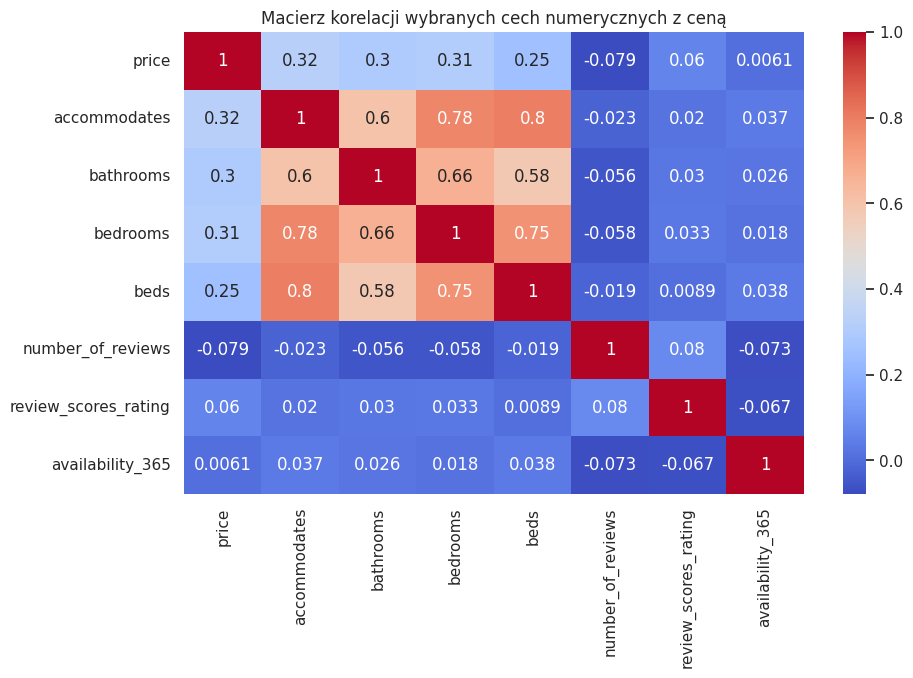

In [ ]:
# Wybór kluczowych kolumn numerycznych do analizy korelacji
numerical_cols = ['price', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
                  'number_of_reviews', 'review_scores_rating', 'availability_365']

correlation = housing[numerical_cols].corr(numeric_only=True)
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2g")
plt.title('Macierz korelacji wybranych cech numerycznych z ceną')
plt.show()


### 8. Preprocessing danych, Inżynieria cech i podział na zbiory

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

features_to_keep = [
    'room_type', 'city', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
    'latitude', 'longitude', 'host_is_superhost', 'host_identity_verified',
    'has_availability', 'availability_30', 'availability_60', 'availability_90',
    'availability_365', 'number_of_reviews', 'number_of_reviews_ltm',
    'number_of_reviews_l30d', 'review_scores_rating', 'reviews_per_month'
]

target = 'price'

X = housing[features_to_keep].copy()
y = housing[target].copy()

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

print(f"Rozmiar X_train po preprocessingu: {X_train_preprocessed.shape}")
print(f"Rozmiar X_test po preprocessingu: {X_test_preprocessed.shape}")

Rozmiar X_train po preprocessingu: (167084, 133)
Rozmiar X_test po preprocessingu: (41772, 133)


### 9. Trening 3 modeli: Linear Regression, Random Forest, XGBoost

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

lr_model = LinearRegression()
lr_model.fit(X_train_preprocessed, y_train)
lr_preds = lr_model.predict(X_test_preprocessed)

# 2. Random Forest (ograniczona liczba estymatorów i głębokość dla przyspieszenia obliczeń)
rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_preprocessed, y_train)
rf_preds = rf_model.predict(X_test_preprocessed)

xgb_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_model.fit(X_train_preprocessed, y_train)
xgb_preds = xgb_model.predict(X_test_preprocessed)

In [ ]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy='median')
baseline_model.fit(X_train_preprocessed, y_train)
baseline_preds = baseline_model.predict(X_test_preprocessed)

Model bazowy przewiduje 136 dla każdej oferty (mediana cen w zbiorze treningowym). Na zbiorze testowym jego MAE wynosi 124,91.

### 10. Porównanie wyników

In [ ]:
results = {
    'Model': ['Baseline (mediana)', 'Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [
        mean_absolute_error(y_test, baseline_preds),
        mean_absolute_error(y_test, lr_preds),
        mean_absolute_error(y_test, rf_preds),
        mean_absolute_error(y_test, xgb_preds)
    ],
    'R2 Score': [
        r2_score(y_test, baseline_preds),
        r2_score(y_test, lr_preds),
        r2_score(y_test, rf_preds),
        r2_score(y_test, xgb_preds)
    ]
}

results_df = pd.DataFrame(results)
display(results_df)

               Model        MAE  R2 Score
0  Baseline (mediana) 124.914560 -0.128456
1   Linear Regression  83.080905  0.579345
2       Random Forest  74.852889  0.642578
3             XGBoost  73.438655  0.652113

Na zbiorze testowym wszystkie trzy modele mają niższe MAE niż baseline (124,91): Linear Regression o 33,5%, Random Forest o 40,1%, a XGBoost o 41,2%. XGBoost wypada najlepiej (MAE 73,44; R² 0,652), ale jego przewaga nad Random Forest jest mała, MAE niższe o 1,41. Wyniki wskazują, że wybrane cechy pomagają przewidywać ceny; nie mówią jednak same w sobie, które cechy powodują ich wzrost.